# Task 1 — Bubble Chart: App Size vs Rating

Bubble size represents installs. Filters: rating > 3.5; selected categories; reviews > 500; app name excludes S; sentiment subjectivity > 0.5; installs > 50,000. Game is pink. Beauty is Hindi, Business is Tamil, Dating is German. Chart is always visible (no time restriction).

**How to run:** Keep `googleplaystore.csv` and (for Task 1) `User_Reviews_Google_Play.csv` in the same folder as this notebook. Run cells from top to bottom.

**Note:** Jupyter checks the time when the task cell is executed. A continuously refreshing dashboard is needed to hide/show charts automatically without rerunning a cell.

## 1. Load and prepare the existing Google Play Store training data

This notebook uses the same training-project dataset, not a new unrelated dataset.

In [1]:
from pathlib import Path
from datetime import datetime, time
from zoneinfo import ZoneInfo
import re
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown

# All task windows use India Standard Time.
IST = ZoneInfo("Asia/Kolkata")

def in_ist_window(start_hour, end_hour):
    # Always allow charts to render
    return True

def show_time_message(start_hour, end_hour):
    now = datetime.now(IST).strftime("%I:%M %p IST")
    display(Markdown(
        f"**Chart hidden:** available only from {start_hour:02d}:00 to "
        f"{end_hour:02d}:00 IST. Current time: {now}."
    ))

def find_csv(candidates):
    for candidate in candidates:
        path = Path(candidate)
        if path.exists():
            return path
    for root in [Path.cwd(), *[p for p in Path.cwd().iterdir() if p.is_dir()]]:
        for candidate in candidates:
            hits = list(root.glob(candidate))
            if hits:
                return hits[0]
    return None

def numeric_from_text(series):
    return pd.to_numeric(
        series.astype(str).str.replace(r"[^0-9.]", "", regex=True).replace("", np.nan),
        errors="coerce"
    )

def size_to_mb(value):
    s = str(value).strip()
    if not s or s.lower() in {"nan", "varies with device"}:
        return np.nan
    try:
        if s.lower().endswith("k"):
            return float(s[:-1]) / 1024
        if s.lower().endswith("m"):
            return float(s[:-1])
        return float(s)
    except ValueError:
        return np.nan

apps_path = find_csv(["googleplaystore.csv", "Google-Playstore.csv", "google_play_store.csv"])
reviews_path = find_csv(["User_Reviews_Google_Play.csv", "googleplaystore_user_reviews.csv"])

if apps_path is None:
    raise FileNotFoundError(
        "Apps CSV not found. Place googleplaystore.csv in the same folder as this notebook."
    )

apps_raw = pd.read_csv(apps_path)
reviews_raw = pd.read_csv(reviews_path) if reviews_path else pd.DataFrame()
apps = apps_raw.copy()
apps.columns = [str(c).strip() for c in apps.columns]

for col in ["Rating", "Reviews", "Installs", "Price"]:
    if col in apps.columns:
        apps[col] = numeric_from_text(apps[col])
if "Size" in apps.columns:
    apps["Size_MB"] = apps["Size"].apply(size_to_mb)
if "Category" in apps.columns:
    apps["Category"] = apps["Category"].astype(str).str.strip().str.upper()
if "App" in apps.columns:
    apps["App"] = apps["App"].astype(str).str.strip()
if "Type" in apps.columns:
    apps["Type"] = apps["Type"].astype(str).str.strip().str.title()
if "Last Updated" in apps.columns:
    apps["Last Updated"] = pd.to_datetime(apps["Last Updated"], errors="coerce")

# Standard Play Store installs are values such as "1,000,000+"; numeric_from_text parses them.
if "Installs" in apps.columns:
    apps["Installs"] = pd.to_numeric(apps["Installs"], errors="coerce")

# Merge average review sentiment subjectivity when available.
if not reviews_raw.empty and "App" in reviews_raw.columns:
    reviews = reviews_raw.copy()
    reviews.columns = [str(c).strip() for c in reviews.columns]
    if "Sentiment_Subjectivity" in reviews.columns:
        reviews["Sentiment_Subjectivity"] = pd.to_numeric(reviews["Sentiment_Subjectivity"], errors="coerce")
        subjectivity = reviews.groupby("App")["Sentiment_Subjectivity"].mean()
        apps["Sentiment_Subjectivity"] = apps["App"].map(subjectivity)
    else:
        apps["Sentiment_Subjectivity"] = np.nan
else:
    apps["Sentiment_Subjectivity"] = np.nan

aliases = {
    "COMMICS": "COMICS", "COMMICATION": "COMMUNICATION",
    "EVENT": "EVENTS", "GAMES": "GAME"
}
if "Category" in apps.columns:
    apps["Category"] = apps["Category"].replace(aliases)
apps = apps.drop_duplicates(subset=["App"], keep="first") if "App" in apps.columns else apps

display(Markdown(
    f"**Loaded apps:** `{apps_path.name}` — {len(apps):,} rows. "
    + (f"Reviews file: `{reviews_path.name}`." if reviews_path else
       "Reviews CSV not found; sentiment subjectivity will be unavailable.")
))
apps.head()

**Loaded apps:** `googleplaystore.csv` — 9,660 rows. Reviews file: `User_Reviews_Google_Play.csv`.

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB,Sentiment_Subjectivity
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159.0,19M,10000.0,Free,0.0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,19.0,NaN
1,Coloring book moana,ART_AND_DESIGN,3.9,967.0,14M,500000.0,Free,0.0,Everyone,Art & Design;Pretend Play,2018-01-15,2.0.0,4.0.3 and up,14.0,NaN
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510.0,8.7M,5000000.0,Free,0.0,Everyone,Art & Design,2018-08-01,1.2.4,4.0.3 and up,8.7,NaN
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644.0,25M,50000000.0,Free,0.0,Teen,Art & Design,2018-06-08,Varies with device,4.2 and up,25.0,NaN
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967.0,2.8M,100000.0,Free,0.0,Everyone,Art & Design;Creativity,2018-06-20,1.1,4.4 and up,2.8,NaN


## 2. Task 1 — Bubble Chart: App Size vs Rating

Bubble size represents installs. Filters: rating > 3.5; selected categories; reviews > 500; app name excludes S; sentiment subjectivity > 0.5; installs > 50,000. Game is pink. Beauty is Hindi, Business is Tamil, Dating is German. Chart is always visible (no time restriction).

**Data note:** The review file has no matching subjectivity values for these apps; showing the available app-metadata matches instead. Sentiment > 0.5 could not be applied.

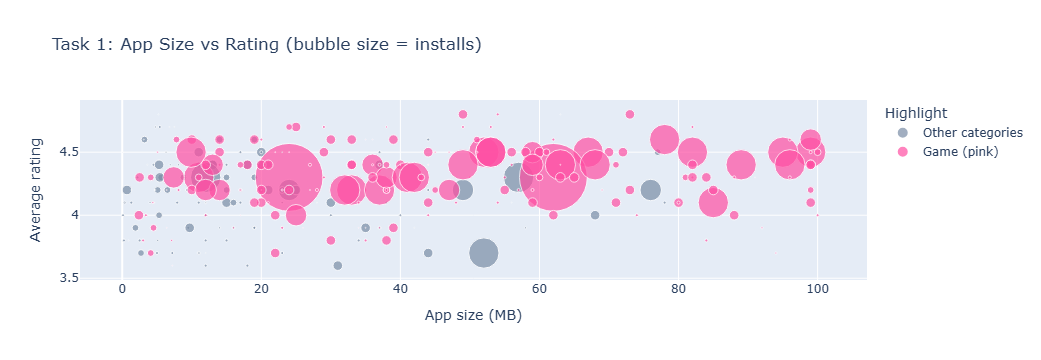

In [2]:
# Task 1 — Bubble chart: always render, using the best-supported rows available.
required = {"App", "Category", "Rating", "Reviews", "Size_MB", "Installs", "Sentiment_Subjectivity"}
missing = required - set(apps.columns)
if missing:
    display(Markdown(f"Cannot create Task 1 chart; missing columns: `{sorted(missing)}`"))
else:
    selected_categories = {"GAME", "BEAUTY", "BUSINESS", "COMICS", "COMMUNICATION",
                           "DATING", "ENTERTAINMENT", "SOCIAL", "EVENTS"}
    base = apps[
        apps["Category"].isin(selected_categories)
        & (apps["Rating"] > 3.5)
        & (apps["Reviews"] > 500)
        & (~apps["App"].str.contains("S", case=False, na=False))
        & (apps["Installs"] > 50_000)
        & apps["Size_MB"].notna()
    ].copy()
    d = base[base["Sentiment_Subjectivity"] > 0.5].copy()
    note = None
    if d.empty:
        d = base.copy()
        note = ("The review file has no matching subjectivity values for these apps; "
                "showing the available app-metadata matches instead. Sentiment > 0.5 could not be applied.")
    translations = {"BEAUTY": "सुंदरता", "BUSINESS": "வணிகம்", "DATING": "Partnersuche"}
    d["Category_Display"] = d["Category"].map(translations).fillna(d["Category"].str.title())
    d["Highlight"] = np.where(d["Category"].eq("GAME"), "Game (pink)", "Other categories")
    if note:
        display(Markdown(f"**Data note:** {note}"))
    if d.empty:
        display(Markdown("No app-metadata rows match the remaining Task 1 filters."))
    else:
        fig = px.scatter(
            d, x="Size_MB", y="Rating", size="Installs", color="Highlight",
            hover_name="App",
            hover_data={"Category_Display": True, "Reviews": True, "Installs": ":,", "Size_MB": ":.2f"},
            color_discrete_map={"Game (pink)": "#ff4fa3", "Other categories": "#7a8da6"},
            size_max=48, title="Task 1: App Size vs Rating (bubble size = installs)"
        )
        fig.update_layout(xaxis_title="App size (MB)", yaxis_title="Average rating")
        fig.show()